# Chargement et préparation des données


In [2]:
#chargement des données


from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.formula.api as smf

DOSSIER_DONNEES = Path("Data nettoyees")
CHEMIN_PRIVE = DOSSIER_DONNEES / "DS_DERA_PRIVE_SERIES_LONGUES_data_nettoye.csv"

if not CHEMIN_PRIVE.is_file():
    raise FileNotFoundError("Fichier privé nettoyé introuvable.")

prive = pd.read_csv(CHEMIN_PRIVE, sep=";", encoding="utf-8-sig")

SALAIRE = 'Salaire net moyen mensuel (Euros constants)'


#construction de l'échantillon 

# Conditions communes
base = (
    prive["indicateur"].eq(SALAIRE)
    & prive["centile_salaire"].eq("Ensemble")
    & prive["geo"].eq("F")
    & prive["secteur_activite"].eq("Ensemble des secteurs")
    & prive["tranche_age"].eq("Ensemble")
    & prive["taille_entreprise"].eq("Ensemble")
    & prive["temps_travail"].eq("Ensemble")
    & prive["sexe"].isin(["Femme", "Homme"])
)

# Échantillon CSP
echantillon_csp = prive.loc[
    base & prive["categorie_socio_prof"].ne("Ensemble"),
    ["annee", "sexe", "categorie_socio_prof", "valeur"]
].copy()

# Échantillon global : évolution temporelle
echantillon_tendance = prive.loc[
    base & prive["categorie_socio_prof"].eq("Ensemble"),
    ["annee", "sexe", "valeur"]
].copy()

# Échantillon par quantile
quantiles = [
    "10e centile (D1 - 10% gagnent moins)",
    "1er quartile (Q1 - 25% gagnent moins)",
    "Médiane (50% gagnent moins/plus)",
    "3e quartile (Q3 - 75% gagnent moins)",
    "90e centile (D9 - 10% gagnent plus)",
    "95e centile (Top 5%)",
    "99e centile (Top 1%)"
]

echantillon_quantiles = prive.loc[
    prive["indicateur"].eq(SALAIRE)
    & prive["centile_salaire"].isin(quantiles)
    & prive["geo"].eq("F")
    & prive["secteur_activite"].eq("Ensemble des secteurs")
    & prive["tranche_age"].eq("Ensemble")
    & prive["taille_entreprise"].eq("Ensemble")
    & prive["temps_travail"].eq("Ensemble")
    & prive["categorie_socio_prof"].eq("Ensemble")
    & prive["sexe"].isin(["Femme", "Homme"]),
    ["annee", "sexe", "centile_salaire", "valeur"]
].copy()

# Préparation commune des variables
for df in [echantillon_csp, echantillon_tendance, echantillon_quantiles]:
    df["annee"] = pd.to_numeric(df["annee"])
    df["valeur"] = pd.to_numeric(df["valeur"])

    df["femme"] = (df["sexe"] == "Femme").astype(int)


def calculer_ecarts(modele, variable, categories, reference):
    resultats = []

    for categorie in categories:
        if categorie == reference:
            continue

        # Coefficient associé à la catégorie
        coef_csp = modele.params.get(
            f"C({variable}, Treatment(reference='{reference}'))[T.{categorie}]",
            0
        )

        # Coefficient d'interaction Femme × catégorie
        coef_interaction = modele.params.get(
            f"femme:C({variable}, Treatment(reference='{reference}'))[T.{categorie}]",
            0
        )

        # Écart total femmes-hommes pour cette catégorie
        ecart_log = modele.params["femme"] + coef_interaction

        # Conversion en pourcentage
        ecart_pct = 100 * (np.exp(ecart_log) - 1)

        resultats.append({
            "CSP": categorie,
            "Écart salarial (%)": ecart_pct
        })

    # Ajouter la catégorie de référence
    ecart_reference = 100 * (np.exp(modele.params["femme"]) - 1)

    resultats.append({
        "CSP": reference,
        "Écart salarial (%)": ecart_reference
    })

    return pd.DataFrame(resultats)

#données des stats descriptives 
MOYENNE = 'Ensemble'
P10 = '10e centile (D1 - 10% gagnent moins)'
P25 = '1er quartile (Q1 - 25% gagnent moins)'
P50 = 'Médiane (50% gagnent moins/plus)'
P90 = '90e centile (D9 - 10% gagnent plus)'
P75 = '3e quartile (Q3 - 75% gagnent moins)'

VALEURS_ENSEMBLE = {
    'secteur_activite': 'Ensemble des secteurs',
    'tranche_age': 'Ensemble',
    'taille_entreprise': 'Ensemble',
    'categorie_socio_prof': 'Ensemble',
    'sexe': 'Ensemble',
    'temps_travail': 'Ensemble',
}

def garder_ensemble_des_autres_dimensions(df, dimension=None):
    for colonne, modalite in VALEURS_ENSEMBLE.items():
        if colonne in df.columns and colonne != dimension:
            df = df[df[colonne] == modalite]
    return df

def extraire_salaire(df, quantiles, dimension=None):
    resultat = garder_ensemble_des_autres_dimensions(df, dimension)
    resultat = resultat[
        (resultat['indicateur'] == SALAIRE)
        & (resultat['unite'] == 'Euros constants')
        & (resultat['centile_salaire'].isin(quantiles))
    ]

    cles = ['annee', 'centile_salaire']
    if dimension:
        cles = [dimension] + cles

    if resultat.duplicated(cles).any():
        raise ValueError(f'Plusieurs valeurs pour les mêmes clés : {cles}')

    return resultat

def serie_quantile(df, quantile, etiquette):
    resultat = extraire_salaire(df, [quantile])
    return resultat[['annee', 'valeur']].rename(
        columns={'valeur': 'Salaire (€ constants)'}
    ).assign(Série=etiquette)

def calculer_ecarts_par_categorie(table, categorie):
    salaires = table.pivot(
        index=['annee', categorie], columns='sexe', values='valeur'
    ).dropna(subset=['Homme', 'Femme'])

    ecart = 100 * (salaires['Homme'] - salaires['Femme']) / salaires['Homme']
    return ecart.unstack(categorie)


# Introduction générale 

Les inégalités salariales entre les femmes et les hommes constituent un enjeu important du marché du travail. Malgré les évolutions observées au cours des dernières décennies, des différences de rémunération persistent entre les deux sexes. Toutefois, ces écarts ne sont pas nécessairement homogènes : ils peuvent varier selon la catégorie socioprofessionnelle, le niveau de rémunération ou encore la période considérée.

L'objectif de cette étude est d'analyser l'évolution et la structure des écarts salariaux entre les femmes et les hommes dans le secteur privé français, sur la période 1996-2024. Pour cela, nous étudierons premièrement l'évolution de l'écart salarial moyen dans le temps. Ensuite, nous identifierons les différences observées selon les catégories socioprofessionnelles (CSP), et enfin, nous examinerons la répartition de ces écarts selon différents niveaux de la distribution des salaires.

Cette approche permet ainsi de mettre en évidence l'hétérogénéité des inégalités salariales. Il convient néanmoins de préciser que les données utilisées sont agrégées et portent sur les salaires mensuels, tous temps de travail confondus. Les résultats doivent donc être interprétés comme des écarts salariaux observés et non comme une mesure directe de l'effet causal du sexe sur la rémunération.

# Statistiques descriptives

On décrit ici les salaires du secteur privé en euros constants.

On regarde l’évolution de l’écart moyen entre les femmes et les hommes, puis on compare les écarts selon le secteur, la catégorie socioprofessionnelle et la position dans la distribution des salaires. 

Ces comparaisons décrivent des écarts agrégés : elles ne mesurent pas un écart de rémunération à poste identique ni ses causes.


## Écart de salaire moyen entre hommes et femmes

On regarde l'écart de salaire moyen : (salaire moyen des hommes − salaire moyen des femmes) / salaire moyen des hommes × 100. Les autres dimensions (secteur, âge, taille d’entreprise, catégorie socioprofessionnelle et temps de travail) sont fixées à « Ensemble ».

Entre 1996 et 2024, l’écart moyen dans le privé diminue de 22,3 % à 13,0 %, soit 9,3 points. Le recul s’accentue après 2015 : l’écart passe alors de 18,0 % à 13,0 % (-5 points). En euros constants, la différence de salaire mensuel moyen est de 583 € en 1996, 518 € en 2015 et 377 € en 2024. La baisse de l’écart relatif indique un rapprochement des moyennes, mais un écart subsiste en 2024. Cela nous invite à affiner avec les secteurs et les CSP. 


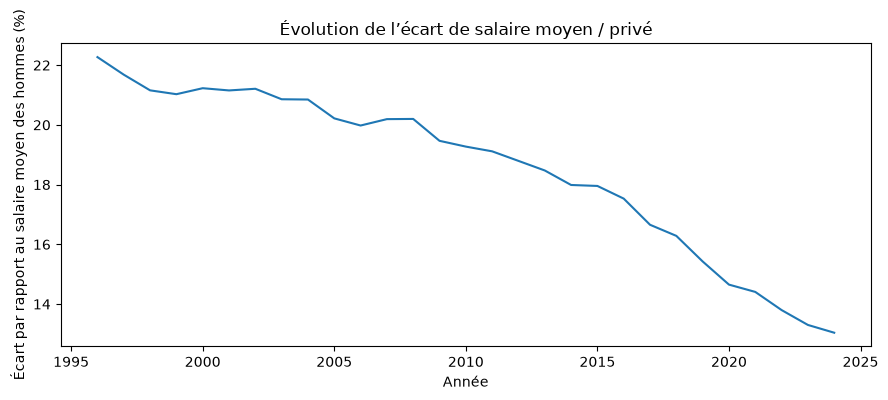

In [3]:
salaires_sexe = extraire_salaire(prive, [MOYENNE], 'sexe')

moyenne_sexe = salaires_sexe.pivot(
    index='annee', columns='sexe', values='valeur'
).dropna()

moyenne_sexe['Écart H-F (% du salaire homme)'] = (
    100 * (moyenne_sexe['Homme'] - moyenne_sexe['Femme']) / moyenne_sexe['Homme']
)

moyenne_sexe['Écart H-F (% du salaire homme)'].plot(figsize=(9, 4))
plt.title('Évolution de l’écart de salaire moyen / privé')
plt.xlabel('Année')
plt.ylabel('Écart par rapport au salaire moyen des hommes (%)')
plt.tight_layout()
plt.show()


## Évolution de l’écart salarial par grande catégorie

### Secteurs

On reprend le même calcul **(salaire moyen des hommes − salaire moyen des femmes) / salaire moyen des hommes × 100**, en regroupant les secteurs. Pour chaque grande catégorie, on calcule une moyenne des salaires moyens des secteurs qui la composent. N'ayant pas les pondérations, on interprètera les résultats avec prudence. 

| Catégorie | Secteurs inclus | Nombre de secteurs regroupés |
|---|---|---:|
| Industrie et Énergie | Industries extractives/énergie/eau/déchets; alimentation/boissons/tabac; cokéfaction-raffinage; produits informatiques/électroniques/machines; matériels de transport; autres industries manufacturières | 6 |
| Construction | Construction | 1 |
| Services marchands | Commerce; transports; hébergement-restauration; information-communication; finance-assurance; immobilier; services aux entreprises (M_N) | 7 |
| Services non marchands et aux ménages | Administration publique/enseignement/santé/action sociale; arts, loisirs et autres services | 2 |

Les autres dimensions (âge, taille, catégorie socioprofessionnelle et temps de travail) restent sur « Ensemble ».

L’écart recule entre 1996 et 2024 dans les quatre catégories. La baisse la plus forte concerne l’Industrie et Énergie, où il passe de 21,0 % à 9,1 %. Dans les services marchands, il diminue de 23,9 % à 15,6 %, et dans les services non marchands et aux ménages, de 24,6 % à 15,1 %. La construction se distingue : l’écart est déjà faible en 1996 (3,8 %), devient négatif à partir de 2015 (-1,3 %) et atteint -2,0 % en 2024. Un écart négatif signifie que la moyenne des femmes est supérieure à celle des hommes dans ce regroupement ; il ne permet pas d’en attribuer la cause, car les métiers, les fonctions et les profils d’emploi peuvent différer.


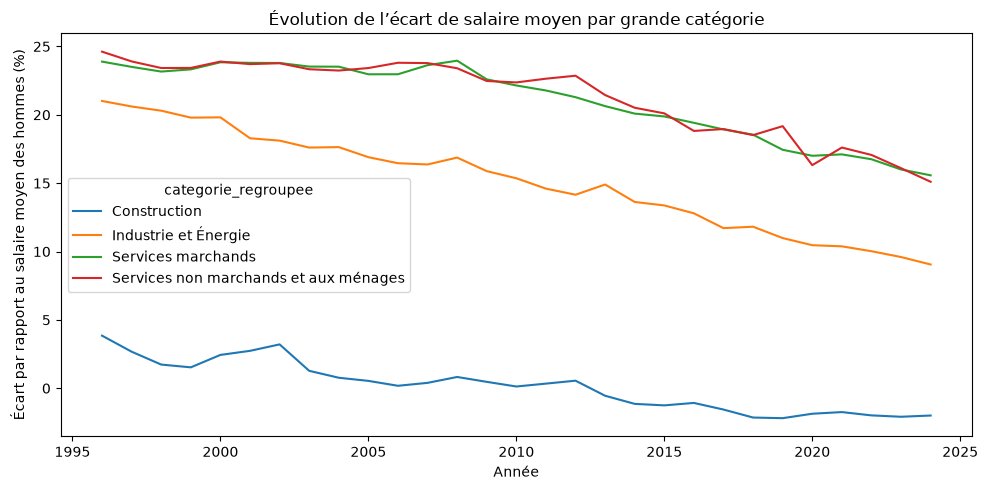

In [4]:
CATEGORIES_SECTEURS = {
    'Industrie et Énergie': [
        'Industries extractives, énergie, eau, déchets (B_D_E)',
        'Fabrication d’aliments, boissons et tabac (C10T12)',
        'Cokéfaction et raffinage (C19)',
        'Fabrication de produits informatiques, électroniques et machines (C26T28)',
        'Fabrication de matériels de transport (C29_30)',
        'Autres industries manufacturières (C_OTH)',
    ],
    'Construction': ['Construction'],
    'Services marchands': [
        'Commerce ; réparation d’automobiles et de motocycles',
        'Transports et entreposage',
        'Hébergement et restauration',
        'Information et communication',
        'Activités financières et d’assurance',
        'Activités immobilières',
        'Activités spécialisées, scientifiques, techniques et services support (M_N)',
    ],
    'Services non marchands et aux ménages': [
        'Administration publique, enseignement, santé et action sociale (OTQ)',
        'Arts, divertissement, loisirs et autres services (R_S)',
    ],
}

secteur_vers_categorie = {
    secteur: categorie
    for categorie, secteurs in CATEGORIES_SECTEURS.items()
    for secteur in secteurs
}

secteurs_manquants = set(secteur_vers_categorie) - set(prive['secteur_activite'].dropna())
if secteurs_manquants:
    raise ValueError(f'Secteurs absents des données : {sorted(secteurs_manquants)}')

salaires_secteurs = prive[
    (prive['indicateur'] == SALAIRE)
    & (prive['unite'] == 'Euros constants')
    & (prive['centile_salaire'] == MOYENNE)
    & (prive['secteur_activite'].isin(secteur_vers_categorie))
    & (prive['sexe'].isin(['Homme', 'Femme']))
    & (prive['tranche_age'] == 'Ensemble')
    & (prive['taille_entreprise'] == 'Ensemble')
    & (prive['categorie_socio_prof'] == 'Ensemble')
    & (prive['temps_travail'] == 'Ensemble')
].copy()

salaires_secteurs['categorie_regroupee'] = salaires_secteurs['secteur_activite'].map(secteur_vers_categorie)

salaires_categories = (
    salaires_secteurs.groupby(['annee', 'categorie_regroupee', 'sexe'])['valeur']
    .mean()
    .reset_index()
)

ecarts_categories = calculer_ecarts_par_categorie(salaires_categories, 'categorie_regroupee')

ecarts_categories.plot(figsize=(10, 5))
plt.title('Évolution de l’écart de salaire moyen par grande catégorie')
plt.xlabel('Année')
plt.ylabel('Écart par rapport au salaire moyen des hommes (%)')
plt.tight_layout()
plt.show()


### Catégorie socioprofessionnelle

On reprend le même indicateur par CSP, en gardant le secteur, l’âge, la taille d’entreprise et le temps de travail sur « Ensemble ».

L’écart moyen diminue dans les quatre CSP entre 1996 et 2024. Il baisse de 27,3 % à 14,7 % chez les cadres, de 19,8 % à 12,5 % chez les ouvriers et de 16,0 % à 11,6 % dans les professions intermédiaires. Les cadres restent donc la catégorie où l’écart moyen est le plus marqué, malgré le recul le plus important en points (-12,6). Ces écarts entre moyennes de groupes ne tiennent pas compte des différences de métiers ou de caractéristiques individuelles au sein de chaque CSP.


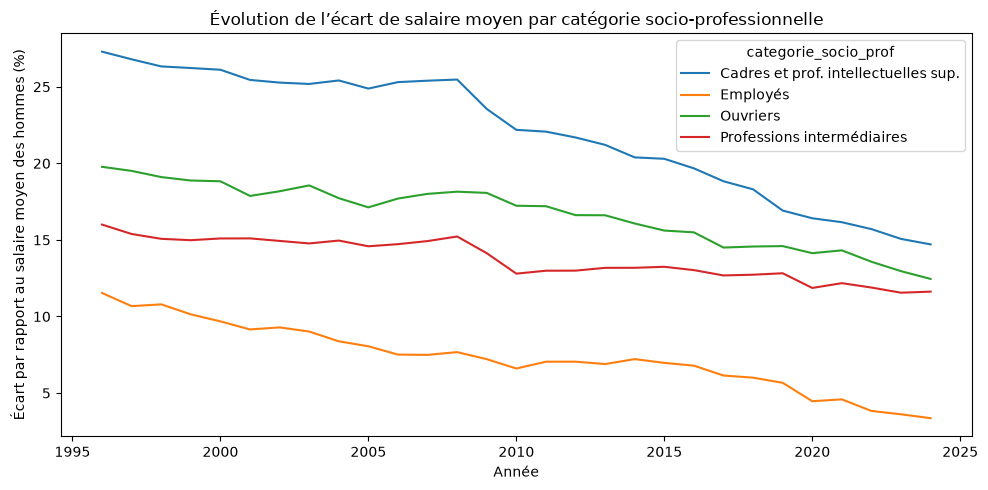

In [5]:
salaires_socioprof = prive[
    (prive['indicateur'] == SALAIRE)
    & (prive['unite'] == 'Euros constants')
    & (prive['centile_salaire'] == MOYENNE)
    & (prive['secteur_activite'] == 'Ensemble des secteurs')
    & (prive['tranche_age'] == 'Ensemble')
    & (prive['taille_entreprise'] == 'Ensemble')
    & (prive['temps_travail'] == 'Ensemble')
    & (prive['categorie_socio_prof'] != 'Ensemble')
    & (prive['sexe'].isin(['Homme', 'Femme']))
].copy()

ecarts_socioprof = calculer_ecarts_par_categorie(salaires_socioprof, 'categorie_socio_prof')

categories_attendues = {
    'Cadres et prof. intellectuelles sup.',
    'Professions intermédiaires',
    'Employés',
    'Ouvriers',
}

if set(ecarts_socioprof.columns) != categories_attendues:
    raise ValueError(f'Catégories absentes : {sorted(categories_attendues - set(ecarts_socioprof.columns))}')

ecarts_socioprof.plot(figsize=(10, 5))
plt.title('Évolution de l’écart de salaire moyen par catégorie socio-professionnelle')
plt.xlabel('Année')
plt.ylabel('Écart par rapport au salaire moyen des hommes (%)')
plt.tight_layout()
plt.show()


## Dispersion des salaires selon le sexe et quantiles

Le ratio **P90/P10** compare le salaire au 90e centile à celui du 10e centile : plus il est élevé, plus la distribution des salaires est dispersée. En 2024, il s’établit à 3,07 chez les hommes et 2,65 chez les femmes. La dispersion est donc plus forte chez les hommes sur toute la période observée. Pour les deux sexes, le ratio atteint un pic en 2020 (3,24 pour les hommes et 2,77 pour les femmes), puis recule. Entre 1996 et 2024, il passe de 3,25 à 3,07 chez les hommes et de 2,53 à 2,65 chez les femmes : les inégalités internes se contractent légèrement chez les hommes, tandis qu’elles augmentent chez les femmes.

Le graphique suivant suit les salaires du P10 au P90 en euros constants. Les niveaux de salaire augmentent globalement sur la période, et la hausse est plus nette dans le haut de la distribution (P75 et P90) que dans le bas (P10 et P25). Le pic de 2020 est particulièrement marqué pour les hauts quantiles ; il coïncide avec le pic du ratio P90/P10. Ces évolutions décrivent les quantiles séparément et ne renseignent pas directement sur la trajectoire des mêmes personnes.


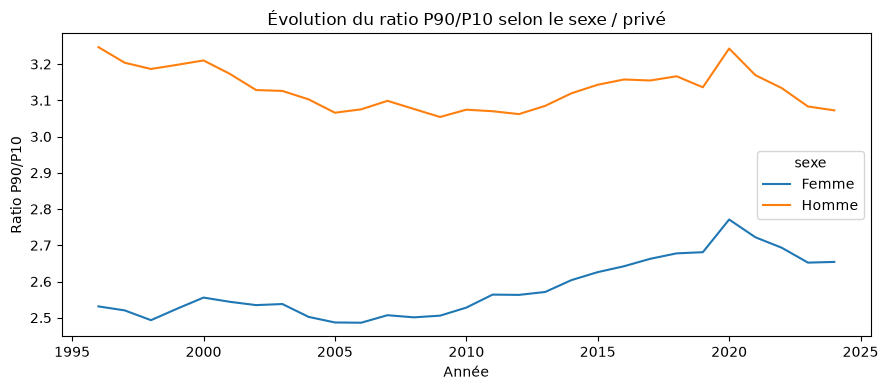

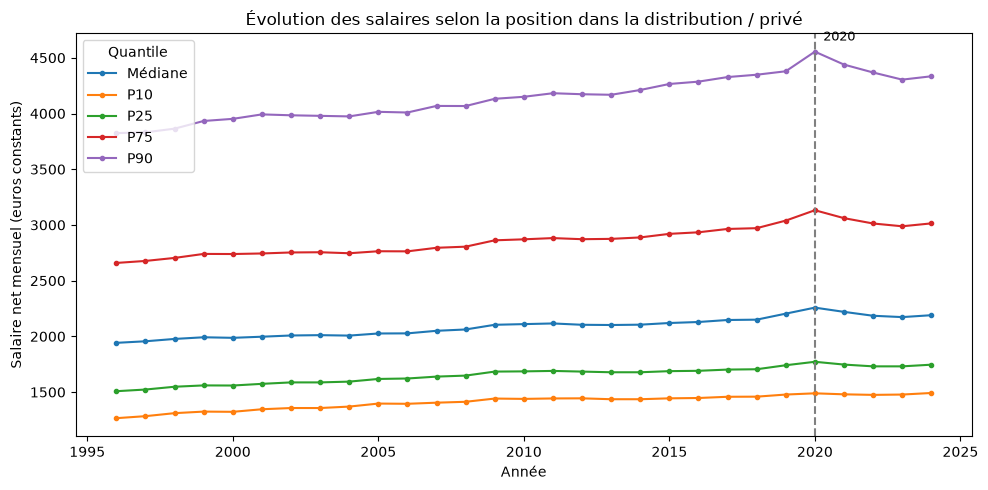

In [8]:
def calculer_ratio_90_10(df, dimension=None):
    table = extraire_salaire(df, [P10, P90], dimension)
    index = ['annee'] if dimension is None else [dimension, 'annee']
    table = table.pivot(index=index, columns='centile_salaire', values='valeur').dropna()
    table['Ratio P90/P10'] = table[P90] / table[P10]
    return table.reset_index()

ratios_sexe = calculer_ratio_90_10(prive, 'sexe')
pivot_ratios_sexe = ratios_sexe[ratios_sexe['sexe'].isin(['Homme', 'Femme'])].pivot(
    index='annee', columns='sexe', values='Ratio P90/P10'
).dropna()

pivot_ratios_sexe.plot(figsize=(9, 4))
plt.title('Évolution du ratio P90/P10 selon le sexe / privé')
plt.xlabel('Année')
plt.ylabel('Ratio P90/P10')
plt.tight_layout()
plt.show()

# Évolution des salaires selon les quantiles
quantiles_a_tracer = [(P10, 'P10'), (P25, 'P25'), (P50, 'Médiane'), (P75, 'P75'), (P90, 'P90')]

series_quantiles = pd.concat(
    [serie_quantile(prive, q, nom) for q, nom in quantiles_a_tracer],
    ignore_index=True
)

pivot_quantiles = series_quantiles.pivot(
    index='annee', columns='Série', values='Salaire (€ constants)'
).sort_index()

ax = pivot_quantiles.plot(figsize=(10, 5), marker='o', markersize=3)

if 2020 in pivot_quantiles.index:
    ax.axvline(2020, color='gray', linestyle='--')
    ax.annotate('2020', (2020, pivot_quantiles.loc[2020, 'P90']), xytext=(6, 8),
                textcoords='offset points', fontsize=9)

plt.title('Évolution des salaires selon la position dans la distribution / privé')
plt.xlabel('Année')
plt.ylabel('Salaire net mensuel (euros constants)')
plt.legend(title='Quantile')
plt.tight_layout()
plt.show()


## Comparaison des salaires aux P10 et P90 selon le sexe

On compare les ratios **P90 des hommes / P90 des femmes** et **P10 des hommes / P10 des femmes**.

Les deux ratios baissent entre 1996 et 2024, mais celui du haut de la distribution reste nettement plus élevé. Au P90, le ratio passe de 1,404 en 1996 à 1,181 en 2024 : le salaire des hommes à ce quantile demeure donc supérieur d’environ 18 % à celui des femmes. Au P10, il passe de 1,095 à 1,020, soit un écart d’environ 2 % en 2024. Le rapprochement est ainsi plus avancé dans le bas de la distribution, tandis que l’écart persiste davantage parmi les hauts salaires.

 (La comparaison porte sur les seuils de la distribution et non sur des salariés identiques)


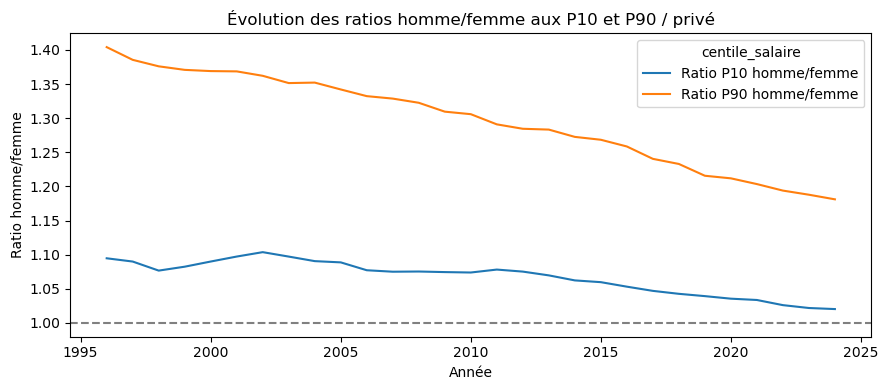

In [6]:
salaires_p10_p90_sexe = extraire_salaire(prive, [P10, P90], 'sexe')
salaires_p10_p90_pivot = salaires_p10_p90_sexe.pivot(
    index=['annee', 'centile_salaire'], columns='sexe', values='valeur'
).dropna(subset=['Homme', 'Femme'])
salaires_p10_p90_pivot['Ratio Homme/Femme'] = (
    salaires_p10_p90_pivot['Homme'] / salaires_p10_p90_pivot['Femme']
)
ratios_p10_p90_sexe = salaires_p10_p90_pivot['Ratio Homme/Femme'].unstack(
    'centile_salaire'
).rename(columns={P10: 'Ratio P10 homme/femme', P90: 'Ratio P90 homme/femme'})

ratios_p10_p90_sexe.plot(figsize=(9, 4))
plt.axhline(1, color='gray', linestyle='--')
plt.title('Évolution des ratios homme/femme aux P10 et P90 / privé')
plt.xlabel('Année')
plt.ylabel('Ratio homme/femme')
plt.tight_layout()
plt.show()


## Part de la masse salariale

Le fichier privé indique la part de la masse salariale perçue par les 10 %, 1 %, 0,1 % et 0,01 % les mieux rémunérés. Cet indicateur décrit la concentration des salaires au sommet de la distribution. (il ne distingue pas les femmes des hommes)

En 2024, le top 10 % reçoit 27,57 % de la masse salariale et le top 1 %, 6,80 % (contre 1,89 % pour le top 0,1 % et 0,56 % pour le top 0,01 %). La part du top 10 % est proche de son niveau de 1996 (27,63 %), après avoir atteint 29,10 % en 2020. Celle du top 1 % a augmenté de 6,05 % en 1996 à 7,43 % en 2015, puis a reculé à 6,80 % en 2024. La concentration au sommet reste donc importante, avec un repli depuis 2020 pour les groupes présentés.


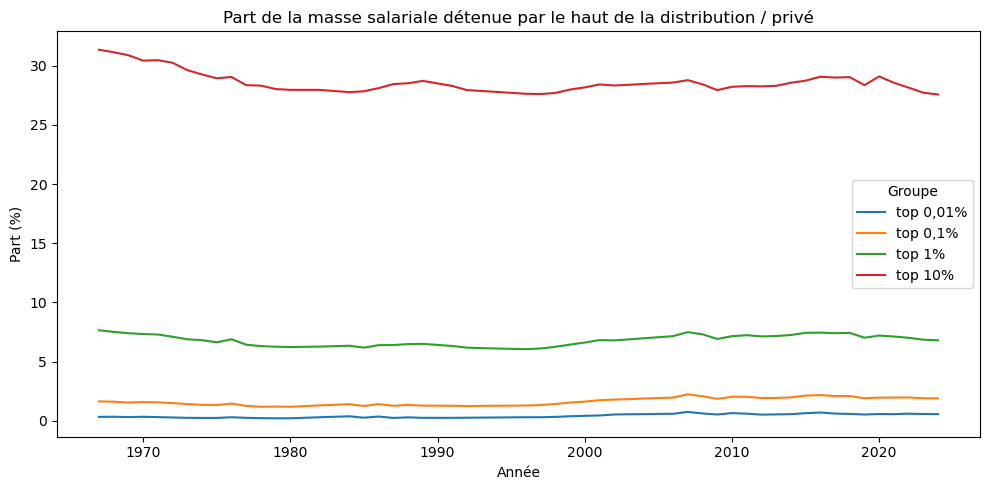

In [7]:
part_top = garder_ensemble_des_autres_dimensions(prive)
part_top = part_top[
    part_top['indicateur'].str.startswith('Part de la masse salariale perçue par le top ')
    & part_top['centile_salaire'].eq('Ensemble')
].copy()
part_top['Groupe'] = part_top['indicateur'].str.extract(r'(top .+)$', expand=False)
part_top = part_top.pivot(index='annee', columns='Groupe', values='valeur')
part_top.plot(figsize=(10, 5))
plt.title('Part de la masse salariale détenue par le haut de la distribution / privé')
plt.xlabel('Année')
plt.ylabel('Part (%)')
plt.tight_layout()
plt.show()


# Analyse par régression


## Régression – L’évolution de l’écart salarial dans le temps

Dans un premier temps, nous cherchons à déterminer si les écarts de rémunération entre les femmes et les hommes se sont réduits au cours des dernières décennies. Pour cela, nous construisons un indicateur correspondant au logarithme du rapport entre le salaire net moyen mensuel des femmes et celui des hommes. Cet indicateur est ensuite régressé sur une tendance temporelle linéaire, afin d'identifier l'évolution moyenne de cet écart sur la période étudiée.


Soit, sous forme mathématique :

$$

\boxed{
\ln\left(\frac{SalaireFemmes_t}{SalaireHommes_t}\right)
=\alpha+\beta \times trend_t+\varepsilon_t
}

$$
Avec :



`trend_t` : tendance temporelle, égale à 0 en 1996 et à 28 en 2024 ;

`alpha` : constante, correspondant à l'écart estimé en 1996 ;

`beta` : évolution annuelle moyenne de l'écart salarial ;

`epsilon_t` : terme d'erreur.












In [8]:
salaire = echantillon_tendance.pivot(
    index="annee", columns="sexe", values="valeur"
)

ecarts = pd.DataFrame({
    "ecart": np.log(salaire["Femme"] / salaire["Homme"])
})

ecarts["trend"] = ecarts.index - 1996

modele_tendance = smf.ols(
    "ecart ~ trend", data=ecarts
).fit(cov_type="HAC", cov_kwds={"maxlags": 1})

print(modele_tendance.summary())

# Interprétation en pourcentage -> !!!!! ça a l'air faut, c'est pas 25% ? à la place de 22%
for terme in ["Intercept", "trend"]:
    beta = modele_tendance.params[terme]
    ic = modele_tendance.conf_int().loc[terme]

    print(
        terme,
        f": {100*np.expm1(beta):.2f} %",
        f"(IC 95 % : {100*np.expm1(ic.iloc[0]):.2f} % ; "
        f"{100*np.expm1(ic.iloc[1]):.2f} %)"
    )

                            OLS Regression Results                            
Dep. Variable:                  ecart   R-squared:                       0.932
Model:                            OLS   Adj. R-squared:                  0.929
Method:                 Least Squares   F-statistic:                     170.8
Date:                Tue, 24 Nov 2026   Prob (F-statistic):           3.44e-13
Time:                        18:31:43   Log-Likelihood:                 96.735
No. Observations:                  29   AIC:                            -189.5
Df Residuals:                      27   BIC:                            -186.7
Df Model:                           1                                         
Covariance Type:                  HAC                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept     -0.2590      0.004    -60.070      0.0

 En 1996, le salaire net moyen mensuel des femmes était inférieur de 22,82 % (A CONFIRMER) à celui des hommes. Ce résultat est statistiquement significatif et témoigne de différences de rémunération déjà marquées au début de la période.

Le coefficient associé à la tendance temporelle est positif et significatif. Il indique que le rapport entre les salaires moyens des femmes et des hommes augmente d'environ 0,38 % par an. Autrement dit, les rémunérations féminines se rapprochent progressivement de celles des hommes et l'écart salarial passerait ainsi de 22,82 % en 1996 à environ 14,1 % (COMMENT ON SAIT) en 2024.

Enfin, le pouvoir explicatif du modèle est relativement élevé, avec un R² de 0,932. Cependant, il convient néanmoins de nuancer ce résultat au regard de la forte autocorrélation positive des résidus, suggérée par une statistique de Durbin-Watson de 0,171. ( A voir si on garde)


## Hétérogénéité des écarts salariaux selon la catégorie socioprofessionnelle

 Nous cherchons à déterminer si les écarts de rémunération varient selon la catégorie socioprofessionnelle. Pour cela, nous réalisons une régression linéaire intégrant des interactions entre le sexe et la CSP, ainsi que des effets fixes annuels. Les ouvriers et les hommes étant les catégories de référence.



$$\boxed{
\ln(Salaire_{it}) =
\alpha+\beta_1 Femme_i
+\gamma_j CSP_{ij}
+\delta_j(Femme_i\times CSP_{ij})
+\lambda_t+\varepsilon_{it}
}$$

 Avec :

`Femme_i` : variable indicatrice égale à 1 pour les femmes et 0 pour les hommes ;

`CSP_ij` : variables indicatrices des catégories socioprofessionnelles ;

`gamma_j` : différences salariales entre les CSP chez les hommes ;

`delta_j` : différences d'écarts salariaux femmes-hommes selon la CSP ;

`lambda_t` : effets fixes annuels ;

`epsilon_it` : terme d'erreur.



In [7]:
modele_csp = smf.ols(
    "np.log(valeur) ~ femme * C(categorie_socio_prof, Treatment(reference='Ouvriers')) + C(annee)",
    data=echantillon_csp
).fit(
    cov_type="cluster",
    cov_kwds={"groups": echantillon_csp["annee"], "use_correction": True}
)

print(modele_csp.summary())

csp = sorted(echantillon_csp["categorie_socio_prof"].unique())

table_csp = calculer_ecarts(
    modele_csp, "categorie_socio_prof", csp, "Ouvriers"
)

display(table_csp.round(3))

                            OLS Regression Results                            
Dep. Variable:         np.log(valeur)   R-squared:                       0.995
Model:                            OLS   Adj. R-squared:                  0.994
Method:                 Least Squares   F-statistic:                 1.793e+04
Date:                Tue, 24 Nov 2026   Prob (F-statistic):           2.22e-49
Time:                        18:06:02   Log-Likelihood:                 518.51
No. Observations:                 232   AIC:                            -965.0
Df Residuals:                     196   BIC:                            -840.9
Df Model:                          35                                         
Covariance Type:              cluster                                         
                                                                                                             coef    std err          z      P>|z|      [0.025      0.975]
---------------------------------------

/usr/local/python/3.14.2/lib/python3.14/site-packages/statsmodels/base/model.py:1988: ValueWarning: covariance of constraints does not have full rank. The number of constraints is 35, but rank is 7
  res = self.wald_test(


,CSP,Écart salarial (%)
0,Cadres et prof. intellectuelles sup.,-22.111
1,Employés,-7.365
2,Professions intermédiaires,-13.756
3,Ouvriers,-16.694


Les résultats font d'abord apparaître des différences importantes de rémunération entre les catégories socioprofessionnelles. Chez les hommes, les cadres perçoivent un salaire mensuel moyen environ 158,5 % supérieur à celui des ouvriers, tandis que l'écart atteint environ 42,7 % pour les professions intermédiaires. En revanche, aucune différence statistiquement significative n'est mise en évidence entre les employés et les ouvriers dans cette spécification.

Au-delà de ces différences entre catégories, les coefficients d'interaction permettent de mettre en évidence une forte hétérogénéité des écarts femmes-hommes. Dans la catégorie de référence, les ouvriers, les femmes perçoivent un salaire mensuel moyen inférieur de 16,69 % à celui des hommes. Cet écart est encore plus important chez les cadres, où il atteint 22,11 %. À l'inverse, il est plus limité chez les professions intermédiaires (-13,76 %) et surtout chez les employés (-7,37 %).

On constate ainsi que les inégalités salariales ont tendance à ne pas être uniformément réparties sur le marché du travail. 

Il faut toutefois rester prudent dans l'interprétation de ces résultats. La catégorie socioprofessionnelle ne permet pas, à elle seule, de contrôler l'ensemble des caractéristiques des emplois occupés. Les différences observées peuvent également refléter des écarts d'ancienneté, de responsabilités, de métiers exercés ou de durée du travail. Il ne s'agit donc pas d'un effet causal de la CSP ou du sexe sur les salaires, mais de différences conditionnelles observées entre groupes.

## Écarts salariaux selon la position dans la distribution des rémunérations

Enfin, la troisième régression vise à étudier la manière dont les écarts salariaux évoluent selon la position des individus dans la distribution des rémunérations. En effet, une comparaison des seuls salaires moyens peut masquer des disparités importantes entre les salariés les moins rémunérés et ceux qui se situent au sommet de la distribution. 

Le modèle est :

$$\boxed{
\ln(Salaire_{itq}) =
\alpha+\beta_1 Femme_i
+\gamma_q Quantile_q
+\delta_q(Femme_i\times Quantile_q)
+\lambda_t+\varepsilon_{itq}
}$$

Avec :

`Femme_i` : variable indicatrice du sexe ;

`Quantile_q` : variables indicatrices des différents quantiles de salaire ;

`gamma_q` : différences salariales entre les quantiles chez les hommes ;

`delta_q` : différences d'écarts femmes-hommes selon le quantile ;

`lambda_t` : effets fixes annuels ;

`epsilon_itq` : terme d'erreur.

La médiane et les hommes constituent respectivement les catégories de référence pour le quantile et le sexe.

In [6]:
reference = "Médiane (50% gagnent moins/plus)"

modele_quantiles = smf.ols(
    f"np.log(valeur) ~ femme * C(centile_salaire, Treatment(reference='{reference}')) + C(annee)",
    data=echantillon_quantiles
).fit(
    cov_type="cluster",
    cov_kwds={"groups": echantillon_quantiles["annee"], "use_correction": True}
)

print(modele_quantiles.summary())

table_quantiles = calculer_ecarts(
    modele_quantiles, "centile_salaire", quantiles, reference
)

display(table_quantiles.round(3))

                            OLS Regression Results                            
Dep. Variable:         np.log(valeur)   R-squared:                       0.999
Model:                            OLS   Adj. R-squared:                  0.998
Method:                 Least Squares   F-statistic:                 4.921e+04
Date:                Tue, 24 Nov 2026   Prob (F-statistic):           2.04e-57
Time:                        18:05:56   Log-Likelihood:                 940.31
No. Observations:                 406   AIC:                            -1797.
Df Residuals:                     364   BIC:                            -1628.
Df Model:                          41                                         
Covariance Type:              cluster                                         
                                                                                                                                 coef    std err          z      P>|z|      [0.025      0.975]
-------------------

/usr/local/python/3.14.2/lib/python3.14/site-packages/statsmodels/base/model.py:1988: ValueWarning: covariance of constraints does not have full rank. The number of constraints is 41, but rank is 13
  res = self.wald_test(


,CSP,Écart salarial (%)
0,10e centile (D1 - 10% gagnent moins),-6.282
1,1er quartile (Q1 - 25% gagnent moins),-9.610
2,3e quartile (Q3 - 75% gagnent moins),-15.986
3,90e centile (D9 - 10% gagnent plus),-22.786
4,95e centile (Top 5%),-27.157
5,99e centile (Top 1%),-34.981
6,Médiane (50% gagnent moins/plus),-12.972


Les résultats révèlent une progression des écarts salariaux à mesure que l'on s'élève dans la distribution des rémunérations. Au premier décile, le salaire des femmes est inférieur de 6,28 % à celui des hommes. Cet écart atteint 12,97 % à la médiane, puis s'accentue progressivement pour atteindre près de 35 % au 99e centile. Les différences estimées sont statistiquement significatives pour l'ensemble des quantiles étudiés.

Cette évolution peut mettre en évidence une concentration des écarts salariaux les plus importants dans le haut de la distribution notamment au 99e centile, les femmes situées à ce niveau de leur distribution salariale perçoivent un salaire inférieur de près de 35 % à celui des hommes situés au même centile.

Ces résultats peuvent notamment conduire à s'interroger sur les différences d'accès aux postes de direction, aux fonctions à forte responsabilité et aux emplois offrant les rémunérations les plus élevées.

Il convient cependant de souligner que notre modèle ne permet pas d'identifier directement les mécanismes à l'origine de ces différences. 

## Conclusion 



L'analyse temporelle met en évidence une réduction significative de l'écart salarial moyen depuis 1996, même si celui-ci demeure important en 2024. Les résultats montrent que ces écarts varient sensiblement selon la catégorie socioprofessionnelle, avec une différence particulièrement marquée chez les cadres. Enfin, l'analyse par quantiles révèle une accentuation progressive des écarts à mesure que l'on se rapproche du sommet de la distribution des salaires.

Ces résultats soulignent ainsi que les inégalités salariales de genre ne peuvent être résumées par un indicateur moyen unique dans la mesure ou leur ampleur dépend à la fois de la position professionnelle et du niveau de rémunération considéré. Il faut toutefois éviter de conclure que ces deux phénomènes concernent nécessairement les mêmes individus, puisque nos données ne permettent pas de croiser simultanément la CSP et les quantiles.

Plusieurs limites à notre analyse doivent ainsi être prises en compte. Les données utilisées sont agrégées et ne permettent pas de contrôler les caractéristiques individuelles des salariés, telles que le diplôme, l'expérience professionnelle, le métier exercé, et des différences de durée du travail, notamment du recours au temps partiel, plus fréquent chez les femmes. Enfin, nos données ne nous permettent pas d'établir un lien de causalité entre le sexe et le niveau de rémunération.
